# Работа с локальным Spark в PySpark

В этом задании используется таблицы на основе данных <a href="https://www.kaggle.com/chicago/chicago-taxi-rides-2016">Chicago Taxi Rides 2016</a>

Схема данных таблицы `taxi_data`:
- taxi_id : идентификатор таксиста
- trip_start_timestamp : время начала поездки
- trip_end_timestamp : время окончания поездки
- trip_seconds : длительности поездки в секундах
- trip_miles : мили пройденные во время поездки
- fare : транспортные расходы
- tips : назначенные чаевые
- trip_total : общая стоимость поездки (с учетом чаевых и транспортных расходов)
- payment_type : тип оплаты

## Инициализация сессии, загрузка данных

In [25]:
from pyspark.sql import SparkSession

spark = SparkSession.builder.appName('BigD_PySpark_Local').getOrCreate()
spark.conf.set("spark.sql.session.timeZone", "GMT+4")

spark

Загрузите файл `taxi_data.parquet` в Spark как объект DataFrame

In [26]:
df = spark.read.parquet("taxi_data.parquet")

## Посчитайте количество загруженных строк.

In [27]:
# Число строк
df.count()

2540712

In [28]:
df.show()

+-------+--------------------+-------------------+------------+----------+-----+-----+----------+------------+
|taxi_id|trip_start_timestamp| trip_end_timestamp|trip_seconds|trip_miles| fare| tips|trip_total|payment_type|
+-------+--------------------+-------------------+------------+----------+-----+-----+----------+------------+
|   5240| 2016-12-16 00:45:00|2016-12-16 01:00:00|         900|       2.5|10.75| 2.45|      14.7| Credit Card|
|   1215| 2016-12-12 08:15:00|2016-12-12 08:15:00|         240|       0.4|  5.0|  3.0|       9.5| Credit Card|
|   3673| 2016-12-16 17:30:00|2016-12-16 18:00:00|        2400|      10.7| 31.0|  0.0|      31.0|        Cash|
|   5400| 2016-12-16 09:45:00|2016-12-16 10:00:00|         300|       0.0| 5.25|  2.0|      7.25| Credit Card|
|   1257| 2016-12-03 19:45:00|2016-12-03 19:45:00|         360|       0.3|  5.0|  0.0|       5.0|        Cash|
|   4666| 2016-12-30 19:00:00|2016-12-30 19:45:00|        2400|      18.2|46.75|10.15|      61.4| Credit Card|
|

Посмотрим схему данных:

In [29]:
df.printSchema()

root
 |-- taxi_id: integer (nullable = true)
 |-- trip_start_timestamp: timestamp (nullable = true)
 |-- trip_end_timestamp: timestamp (nullable = true)
 |-- trip_seconds: integer (nullable = true)
 |-- trip_miles: double (nullable = true)
 |-- fare: double (nullable = true)
 |-- tips: double (nullable = true)
 |-- trip_total: double (nullable = true)
 |-- payment_type: string (nullable = true)



## Чему равна корреляция и ковариация между длиной маршрута и ценой за поездку? Ответ округлите до 5 знаков после запятой.

См. `corr` и `cov`

In [37]:
corr = df.stat.corr("trip_miles", "trip_total")
cov = df.stat.cov("trip_miles", "trip_total")

corr_rounded = __builtins__.round(corr, 5)
cov_rounded = __builtins__.round(cov, 5)

corr_rounded, cov_rounded

(0.44816, 71.96914)

## Найдите количество, среднее, cреднеквадратическое отклонение, минимум и максимум для длины маршрута и цены за поездку? Ответ округлите до 1 знака после запятой.

См. `describe`

In [38]:
# Ваш код
df.select("trip_miles", "trip_total").describe().toPandas().round(1)

,summary,trip_miles,trip_total
0,count,2540677,2540672
1,mean,3.0005873828090266,15.913560215564042
2,stddev,5.25716922943536,30.546699217618237
3,min,0.0,0.0
4,max,900.0,9276.69


## Найдите самый НЕ популярный вид оплаты.

См. `groupBy` и `orderBy`

In [39]:
# Ваш код
from pyspark.sql.functions import col

In [40]:
df.groupBy("payment_type").count().orderBy(col("count").asc()).show(1)

+------------+-----+
|payment_type|count|
+------------+-----+
|    Way2ride|    3|
+------------+-----+
only showing top 1 row



## Найдите идентификатор таксиста выполнившего наибольшее число заказов.

In [41]:
# Ваш код
df.groupBy("taxi_id").count().orderBy(col("count").desc()).show(1)

+-------+-----+
|taxi_id|count|
+-------+-----+
|    316| 2225|
+-------+-----+
only showing top 1 row



## Чему равна средняя цена среди поездок, оплаченных наличными? Ответ округлите до 5 знака.

См. `where`

In [42]:
# Ваш код
from pyspark.sql.functions import avg

In [43]:
df.where(col("payment_type") == "Cash").select(round(avg("trip_total"), 5).alias("avg_cash_price")).show()

+--------------+
|avg_cash_price|
+--------------+
|      12.03526|
+--------------+



## Сколько таксистов проехало больше 1000 миль за все время выполнения заказов?

In [44]:
# Ваш код
df.groupBy("taxi_id").sum("trip_miles").where(col("sum(trip_miles)") > 1000).count()

2860

## Сколько миль проехал пассажир в самой долгой поездке? (Ответ округлите до целого)

In [45]:
# Ваш код
from pyspark.sql.functions import round

In [50]:
df.orderBy(col("trip_seconds").desc()) \
  .select(round("trip_miles").alias("miles"), "trip_seconds") \
  .show(1)

+-----+------------+
|miles|trip_seconds|
+-----+------------+
|  0.0|       86399|
+-----+------------+
only showing top 1 row



## Каков средний заработок всех таксистов? Ответ округлите до 5-ого знака.

Исключите из рассмотрения неизвестные машины (для которых не определён taxi_id).

In [47]:
# Ваш код
df_clean = df.where(col("taxi_id").isNotNull())

In [48]:
df_clean.groupBy("taxi_id").sum("trip_total").select(round(avg("sum(trip_total)"), 5).alias("avg_driver_income")).show()

+-----------------+
|avg_driver_income|
+-----------------+
|       8218.85627|
+-----------------+



## Сколько поездок начиналось в самый загруженный час?

См. `hour`

In [28]:
from pyspark.sql.functions import hour

In [29]:
# Ваш 
df.withColumn("hour", hour("trip_start_timestamp")).groupBy("hour").count().orderBy(col("count").desc()).show(1)

+----+------+
|hour| count|
+----+------+
|  19|181127|
+----+------+
only showing top 1 row



## Сколько поездок началось во второй четверти суток?

In [32]:
# Ваш код
df.withColumn("hour", hour("trip_start_timestamp")).where((col("hour") >= 6) & (col("hour") <= 11)).count()

438297

## Найдите топ три даты, в которые было суммарно больше всего чаевых? (Чаевые выдаются после совершения поездки)

Ожидаемый формат дат 'YYYY-MM-DD'

Может понадобиться конвертация типов `cast`

In [34]:
from pyspark.sql.types import DateType
from pyspark.sql.functions import to_date, sum as _sum

In [36]:
# Ваш код
df.withColumn("date", to_date("trip_end_timestamp")).groupBy("date").agg(_sum("tips").alias("total_tips")).orderBy(col("total_tips").desc()).show(3)

+----------+------------------+
|      date|        total_tips|
+----------+------------------+
|2016-11-03|110412.16000000005|
|2016-11-09|105641.03999999986|
|2016-11-16| 98822.25000000035|
+----------+------------------+
only showing top 3 rows



## Сколько было заказов в дату с наибольшим спросом?

In [55]:
# Ваш код
top_date = df.withColumn("date", to_date("trip_start_timestamp")).groupBy("date").count().orderBy(col("count").desc()).limit(1)

In [56]:
top_date.show()

+----------+-----+
|      date|count|
+----------+-----+
|2016-11-03|61111|
+----------+-----+



Подгрузите данные о марках машин из файла `taxi_cars_data.parquet`

In [40]:
df_car = spark.read.parquet("taxi_cars_data.parquet")

In [41]:
df_car.show()

+-------+-------------------+
|taxi_id|          car_model|
+-------+-------------------+
|   1159|       Toyota Prius|
|   7273|Ford Crown Victoria|
|   2904|        Honda Civic|
|   3210|        Ford Fusion|
|   2088|       Toyota Camry|
|   4821|Ford Crown Victoria|
|   2069|    Hyundai Elantra|
|   6240|       Toyota Camry|
|    296|     Hyundai Sonata|
|   2136|Ford Crown Victoria|
|   1436|     Toyota Corolla|
|   1090|     Toyota Corolla|
|   7711|        Lincoln MKZ|
|   1572|Ford Crown Victoria|
|   3959|     Chevrolet Aveo|
|   5645|  Chevrolet Lacetti|
|   5149|            Audi A7|
|   6366|     Hyundai Sonata|
|    451|     Hyundai Accent|
|   1669|           Kia Ceed|
+-------+-------------------+
only showing top 20 rows



## Какая марка машины самая распространённая среди таксистов?

См. `split`

In [50]:
from pyspark.sql.functions import split, col

In [52]:
df_car \
    .withColumn("brand", split(col("car_model"), " ").getItem(0)) \
    .groupBy("brand") \
    .count() \
    .orderBy(col("count").desc()) \
    .show(1)

+-----+-----+
|brand|count|
+-----+-----+
| Ford| 1484|
+-----+-----+
only showing top 1 row



## Сколько раз и какая модель машин чаще всего встречается в поездках?

См. `join`

In [47]:
# Ваш код
df_join = df.join(df_car, on="taxi_id", how="inner")

In [54]:
df_join.groupBy("car_model").count().orderBy(col("count").desc()).show(1)

+-------------------+------+
|          car_model| count|
+-------------------+------+
|Ford Crown Victoria|388682|
+-------------------+------+
only showing top 1 row



## Откройте SparkUI по адресу localhost:4040 и изучите историю выполнения задач.

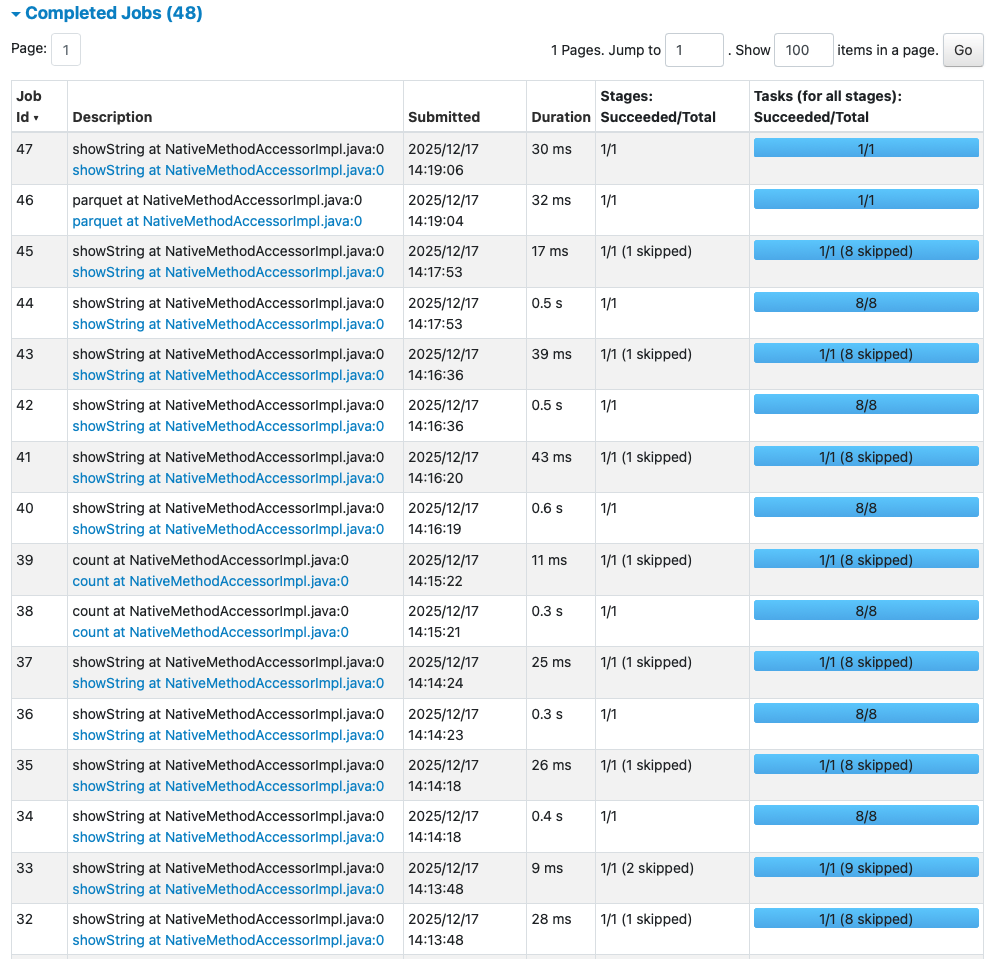
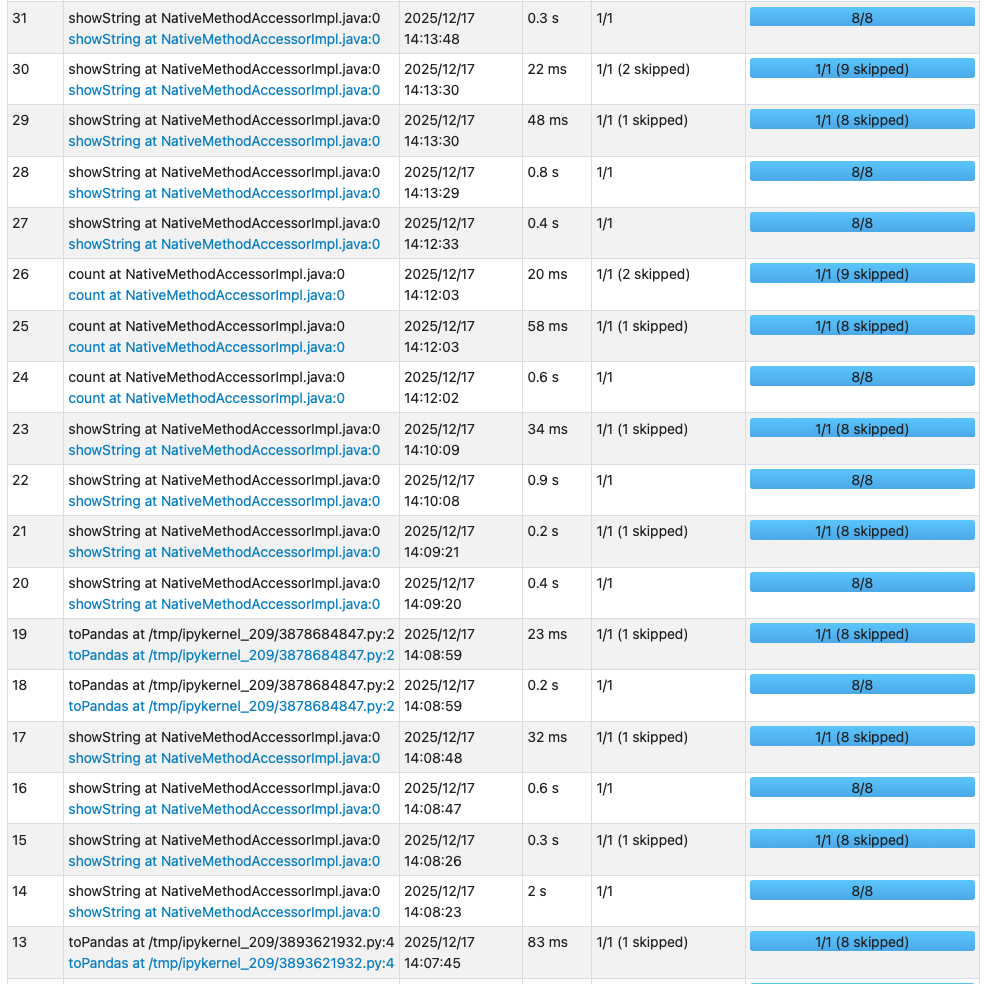
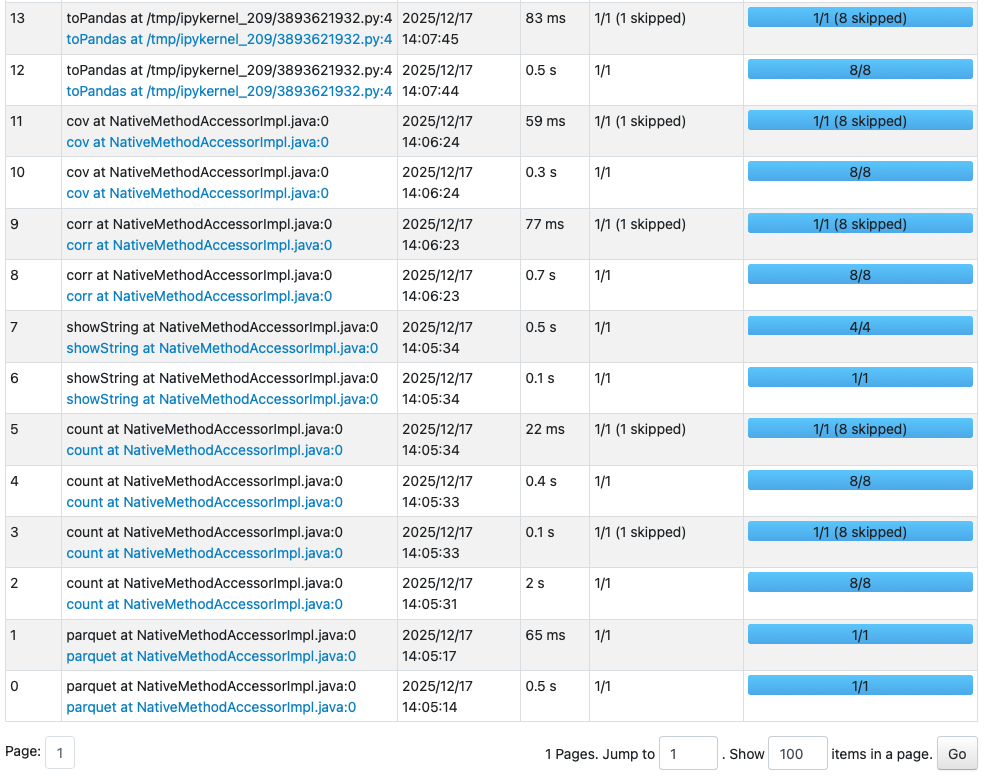

In [ ]:
spark